<a href="https://colab.research.google.com/github/dwcss/pm-turi4-clustering-DawwasZakkaSutiono./blob/main/PM_P9_Dawwas_Zakka_Sutiono_2488010015.ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>

# Praktikum Pertemuan 9 — Clustering dengan K-Means

| **Mata Kuliah** | Pembelajaran Mesin |
| **Kode Mata Kuliah** | INF62325 |
| **Nama** | Dawwas Zakka Sutiono |
| **NIM** | 2488010015 |
| **Kelas** | Informatika 5B |



## Bagian 2 — Import Library


In [1]:
# Jika dijalankan di lingkungan lain yang belum memiliki library, hapus tanda # pada baris berikut.
# !pip install -q numpy pandas matplotlib seaborn scikit-learn

import warnings
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns

from sklearn.preprocessing import StandardScaler
from sklearn.cluster import KMeans
from sklearn.metrics import silhouette_score, silhouette_samples, adjusted_rand_score

warnings.filterwarnings("ignore")
sns.set_theme(style="whitegrid")
plt.rcParams["figure.dpi"] = 100

RANDOM_STATE = 42
FITUR = ["usia", "pendapatan", "skor_belanja"]

print("Library berhasil diimpor.")

Library berhasil diimpor.


## Bagian 3 — Membuat Dataset Segmentasi Pelanggan


In [2]:
# Membuat dataset sintetis segmentasi pelanggan (TANPA kolom label asli).
# Tiga kelompok pelanggan dibangkitkan dari distribusi normal berbeda, lalu digabung dan diacak.
rng = np.random.default_rng(RANDOM_STATE)

def bangkitkan_kelompok(n, usia, pendapatan, skor):
    """Membangkitkan n pelanggan; setiap argumen berupa pasangan (rata-rata, simpangan baku)."""
    return pd.DataFrame({
        "usia": rng.normal(*usia, n),
        "pendapatan": rng.normal(*pendapatan, n),
        "skor_belanja": rng.normal(*skor, n),
    })

df = pd.concat([
    bangkitkan_kelompok(100, (27, 5), (220, 40), (78, 9)),
    bangkitkan_kelompok(100, (48, 7), (230, 45), (30, 10)),
    bangkitkan_kelompok(100, (38, 9), (90, 25), (50, 12)),
], ignore_index=True)

# Membatasi nilai ke rentang yang masuk akal, lalu membulatkan
df["usia"] = df["usia"].clip(18, 70).round().astype(int)
df["pendapatan"] = df["pendapatan"].clip(30, None).round(1)
df["skor_belanja"] = df["skor_belanja"].clip(1, 100).round().astype(int)

# Mengacak urutan baris agar tidak terurut per kelompok; asal kelompok tidak disimpan sebagai kolom
df = df.sample(frac=1, random_state=RANDOM_STATE).reset_index(drop=True)

print("Lima baris pertama:")
display(df.head())
print("\nUkuran dataset (baris, kolom):", df.shape)
print("\nInformasi tipe data:")
df.info()
print("\nStatistik deskriptif:")
display(df.describe().round(2))
print("\nJumlah nilai kosong per kolom:")
print(df.isna().sum())

Lima baris pertama:


,usia,pendapatan,skor_belanja
0,32,88.6,55
1,23,92.1,34
2,44,317.8,33
3,23,150.9,75
4,21,85.3,45



Ukuran dataset (baris, kolom): (300, 3)

Informasi tipe data:
<class 'pandas.core.frame.DataFrame'>
RangeIndex: 300 entries, 0 to 299
Data columns (total 3 columns):
 #   Column        Non-Null Count  Dtype  
---  ------        --------------  -----  
 0   usia          300 non-null    int64  
 1   pendapatan    300 non-null    float64
 2   skor_belanja  300 non-null    int64  
dtypes: float64(1), int64(2)
memory usage: 7.2 KB

Statistik deskriptif:


,usia,pendapatan,skor_belanja
count,300.00,300.00,300.00
mean,37.49,179.50,51.48
std,11.42,72.93,22.55
min,18.00,33.00,1.00
25%,28.00,109.02,33.00
50%,35.50,194.10,49.00
75%,47.00,234.15,72.00
max,64.00,346.90,100.00



Jumlah nilai kosong per kolom:
usia            0
pendapatan      0
skor_belanja    0
dtype: int64


**Hasil:** dataset berukuran **300 baris × 3 kolom**, seluruh kolom bertipe numerik (`usia` dan `skor_belanja` bertipe integer, `pendapatan` bertipe float), dan **tidak ada nilai kosong**. Rata-rata `usia` ≈ 37,5 tahun, `pendapatan` ≈ 179,5 juta Rp/tahun, dan `skor_belanja` ≈ 51,5. Perhatikan bahwa rentang ketiga fitur sangat berbeda: `pendapatan` berkisar 33–346,9, sedangkan `usia` hanya 18–64

## Bagian 4 — Persiapan Data dan Scaling


Data SEBELUM scaling (5 baris pertama):


,usia,pendapatan,skor_belanja
0,32,88.6,55
1,23,92.1,34
2,44,317.8,33
3,23,150.9,75
4,21,85.3,45



Data SESUDAH scaling (5 baris pertama):


,usia,pendapatan,skor_belanja
0,-0.481,-1.249,0.156
1,-1.271,-1.200,-0.776
2,0.571,1.900,-0.821
3,-1.271,-0.393,1.045
4,-1.446,-1.294,-0.288



Perbandingan skala fitur:


,mean_sebelum,std_sebelum,min_sebelum,max_sebelum,mean_sesudah,std_sesudah,min_sesudah,max_sesudah
usia,37.487,11.398,18.0,64.0,0.0,1.0,-1.710,2.326
pendapatan,179.503,72.807,33.0,346.9,-0.0,1.0,-2.012,2.299
skor_belanja,51.480,22.516,1.0,100.0,0.0,1.0,-2.242,2.155


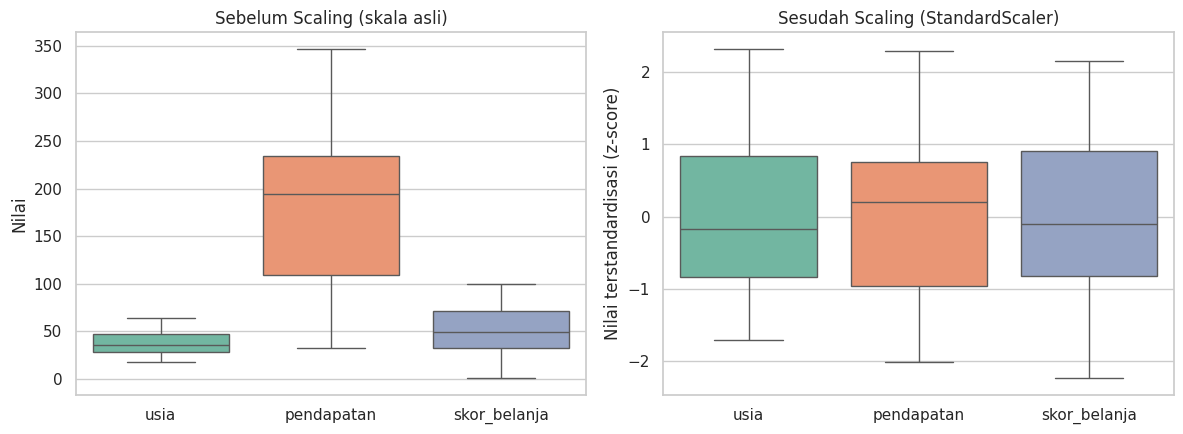

In [3]:
# Memilih fitur clustering (tanpa label) dan melakukan standardisasi
X = df[FITUR].copy()

scaler = StandardScaler()
X_scaled = scaler.fit_transform(X)
X_scaled_df = pd.DataFrame(X_scaled, columns=FITUR)

print("Data SEBELUM scaling (5 baris pertama):")
display(X.head())
print("\nData SESUDAH scaling (5 baris pertama):")
display(X_scaled_df.head().round(3))

# Perbandingan skala tiap fitur sebelum dan sesudah scaling
perbandingan = pd.DataFrame({
    "mean_sebelum": X.mean(), "std_sebelum": X.std(ddof=0),
    "min_sebelum": X.min(), "max_sebelum": X.max(),
    "mean_sesudah": X_scaled_df.mean(), "std_sesudah": X_scaled_df.std(ddof=0),
    "min_sesudah": X_scaled_df.min(), "max_sesudah": X_scaled_df.max(),
}).round(3)
print("\nPerbandingan skala fitur:")
display(perbandingan)

# Visualisasi perbandingan skala
fig, axes = plt.subplots(1, 2, figsize=(12, 4.5))
sns.boxplot(data=X, ax=axes[0], palette="Set2")
axes[0].set_title("Sebelum Scaling (skala asli)")
axes[0].set_ylabel("Nilai")
sns.boxplot(data=X_scaled_df, ax=axes[1], palette="Set2")
axes[1].set_title("Sesudah Scaling (StandardScaler)")
axes[1].set_ylabel("Nilai terstandardisasi (z-score)")
plt.tight_layout()
plt.show()

**Hasil dan analisis:** Sebelum scaling, simpangan baku `pendapatan` (≈ 72,8) jauh lebih besar daripada `skor_belanja` (≈ 22,5) dan `usia` (≈ 11,4). Setelah scaling, ketiganya memiliki rata-rata 0 dan simpangan baku 1.

**Mengapa scaling wajib pada K-Means?** K-Means menetapkan anggota cluster melalui jarak Euclidean. Fitur berskala besar akan mendominasi nilai jarak, sedangkan fitur berskala kecil nyaris diabaikan, padahal besar kecilnya satuan tidak mencerminkan tingkat kepentingan fitur. Standardisasi menyamakan kontribusi setiap fitur sehingga jarak mencerminkan kemiripan secara seimbang.

## Bagian 5 — Menentukan K dengan Metode Elbow
**Inertia** (*within-cluster sum of squares*) adalah jumlah kuadrat jarak setiap titik ke centroid clusternya. Nilainya selalu menurun ketika K bertambah, sehingga K tidak boleh dipilih hanya dari inertia terkecil. Yang dicari adalah **titik siku**, yaitu K setelah mana penurunan inertia melandai tajam. Sebagai pembanding objektif, tabel di bawah juga memuat persentase penurunan inertia dan Silhouette Score untuk setiap K.

,K,inertia,silhouette,penurunan_inertia,penurunan_%
0,1,900.000,NaN,NaN,NaN
1,2,503.480,0.405,396.520,44.058
2,3,253.620,0.507,249.859,49.626
3,4,209.819,0.443,43.802,17.271
4,5,182.359,0.383,27.460,13.087
5,6,163.342,0.285,19.017,10.428
6,7,148.502,0.283,14.840,9.085
7,8,141.787,0.256,6.715,4.522
8,9,128.070,0.275,13.717,9.674
9,10,119.838,0.282,8.232,6.428


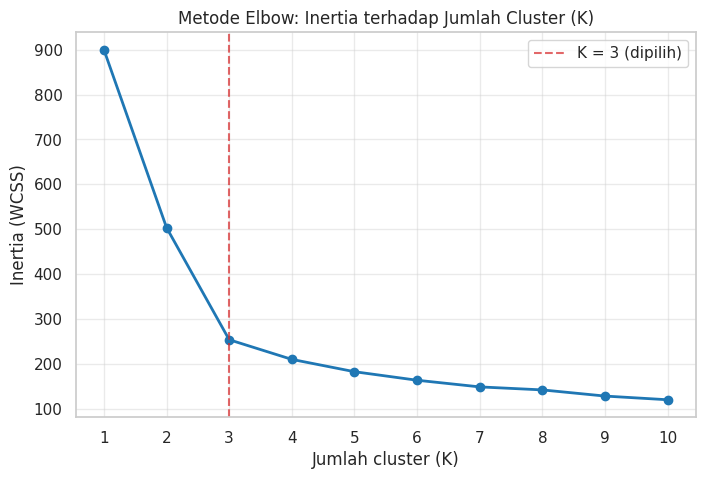

K dengan Silhouette Score tertinggi (pembanding tambahan): K = 3


In [4]:
# Fungsi bantu: Silhouette Score hanya valid jika 2 <= jumlah cluster terbentuk <= n_sampel - 1
def hitung_silhouette(data, label):
    n_cluster = len(np.unique(label))
    if n_cluster < 2 or n_cluster > len(data) - 1:
        print(f"Silhouette Score tidak dapat dihitung: jumlah cluster = {n_cluster} (harus 2 .. {len(data) - 1}).")
        return np.nan
    return silhouette_score(data, label)

# Metode Elbow: uji K = 1 sampai 10 pada data yang sudah di-scaling
K_RANGE = range(1, 11)
inertias, siluet_per_k = [], []
for k in K_RANGE:
    km = KMeans(n_clusters=k, random_state=RANDOM_STATE, n_init=10)
    km.fit(X_scaled)
    inertias.append(km.inertia_)
    # Silhouette tidak terdefinisi untuk K=1, maka dilewati (NaN) tanpa memunculkan error
    siluet_per_k.append(silhouette_score(X_scaled, km.labels_) if k >= 2 else np.nan)

tabel_elbow = pd.DataFrame({"K": list(K_RANGE), "inertia": inertias, "silhouette": siluet_per_k})
tabel_elbow["penurunan_inertia"] = tabel_elbow["inertia"].diff().abs()
tabel_elbow["penurunan_%"] = (tabel_elbow["inertia"].pct_change().abs() * 100)
display(tabel_elbow.round(3))

# Grafik Elbow
plt.figure(figsize=(8, 5))
plt.plot(list(K_RANGE), inertias, marker="o", linewidth=2, color="tab:blue")
plt.axvline(3, color="tab:red", linestyle="--", alpha=0.7, label="K = 3 (dipilih)")
plt.title("Metode Elbow: Inertia terhadap Jumlah Cluster (K)")
plt.xlabel("Jumlah cluster (K)")
plt.ylabel("Inertia (WCSS)")
plt.xticks(list(K_RANGE))
plt.grid(True, alpha=0.4)
plt.legend()
plt.show()

K_siluet_terbaik = int(tabel_elbow.loc[tabel_elbow["silhouette"].idxmax(), "K"])
print(f"K dengan Silhouette Score tertinggi (pembanding tambahan): K = {K_siluet_terbaik}")

**Hasil dan analisis grafik Elbow:**
- Inertia turun dari 900,0 (K=1) menjadi 503,5 (K=2), lalu 253,6 (K=3), kemudian 209,8 (K=4).
- Penurunan dari K=2 ke K=3 sebesar **49,6%**, sedangkan dari K=3 ke K=4 hanya **17,3%**, dan seterusnya semakin kecil (13,1%, 10,4%, ...). Perubahan kemiringan paling tajam terjadi pada K=3 sehingga grafik memperlihatkan **siku yang cukup jelas di K=3**.
- Secara tambahan, Silhouette Score tertinggi juga dicapai pada K=3 (0,507), lebih tinggi dibandingkan K=2 (0,405) dan K=4 (0,443). Dua indikator yang berbeda mendukung pilihan yang sama.

**Catatan objektivitas:** Kejelasan siku di K=3 pada data ini wajar karena dataset sintetis dibangkitkan dari tiga kelompok. Pada data nyata, siku sering kurang tegas dan keputusan sebaiknya dikombinasikan dengan evaluasi lain serta kebutuhan bisnis. Untuk analisis utama dipilih **K=3**.

## Bagian 6 — Implementasi K-Means dengan K=3


Data beserta label cluster (10 baris pertama):


,usia,pendapatan,skor_belanja,cluster
0,32,88.6,55,2
1,23,92.1,34,2
2,44,317.8,33,1
3,23,150.9,75,0
4,21,85.3,45,2
5,34,97.1,50,2
6,53,147.6,25,1
7,60,171.7,35,1
8,20,211.8,78,0
9,64,214.7,15,1



Jumlah anggota setiap cluster:
cluster
0    102
1     96
2    102
Name: count, dtype: int64

Centroid (ruang ter-scaling, satuan z-score):


,usia,pendapatan,skor_belanja
cluster,,,
0,-0.929,0.525,1.153
1,1.027,0.707,-1.002
2,-0.038,-1.190,-0.210


Centroid (dikembalikan ke skala asli):


,usia,pendapatan,skor_belanja
cluster,,,
0,26.9,217.7,77.5
1,49.2,231.0,28.9
2,37.1,92.9,46.7



Inertia model K=3: 253.62 | Iterasi hingga konvergen: 6


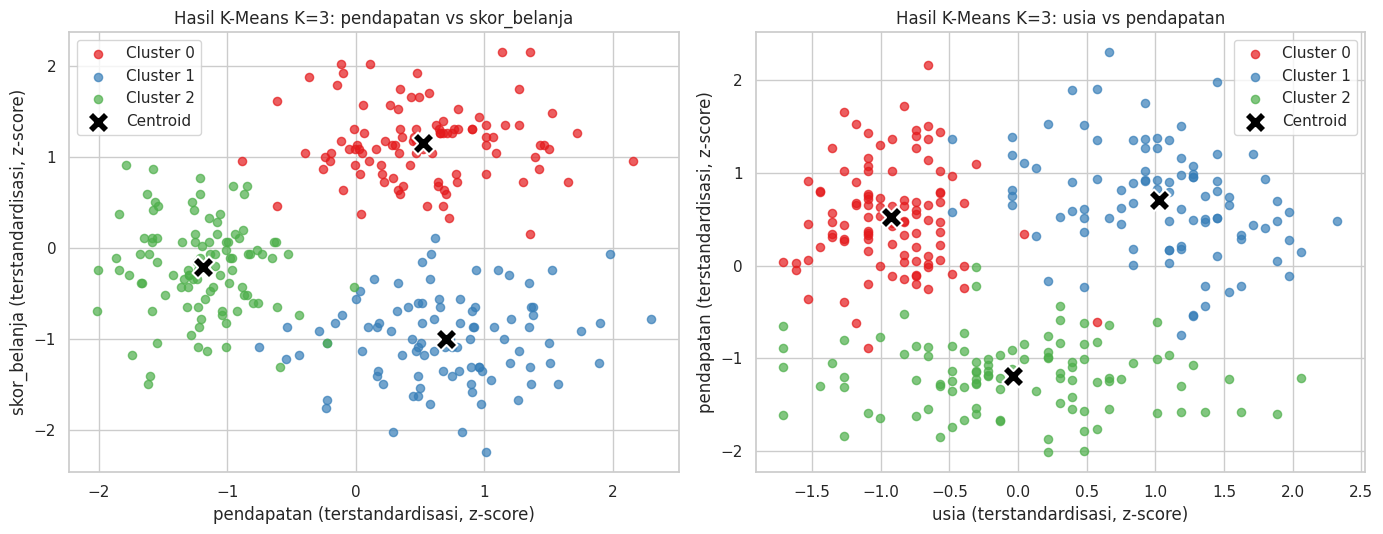

In [5]:
# K-Means dengan K = 3 pada data ter-scaling
kmeans = KMeans(n_clusters=3, random_state=RANDOM_STATE, n_init=10)
df["cluster"] = kmeans.fit_predict(X_scaled)

print("Data beserta label cluster (10 baris pertama):")
display(df.head(10))

print("\nJumlah anggota setiap cluster:")
print(df["cluster"].value_counts().sort_index())

# Centroid dalam ruang ter-scaling dan dikembalikan ke skala asli
centroid_scaled = pd.DataFrame(kmeans.cluster_centers_, columns=FITUR).round(3)
centroid_asli = pd.DataFrame(scaler.inverse_transform(kmeans.cluster_centers_), columns=FITUR).round(1)
centroid_scaled.index.name = centroid_asli.index.name = "cluster"
print("\nCentroid (ruang ter-scaling, satuan z-score):")
display(centroid_scaled)
print("Centroid (dikembalikan ke skala asli):")
display(centroid_asli)
print(f"\nInertia model K=3: {kmeans.inertia_:.2f} | Iterasi hingga konvergen: {kmeans.n_iter_}")

# Visualisasi pada ruang ter-scaling (dua sudut pandang)
palet = sns.color_palette("Set1", 3)
fig, axes = plt.subplots(1, 2, figsize=(14, 5.5))
pasangan = [("pendapatan", "skor_belanja"), ("usia", "pendapatan")]
for ax, (fx, fy) in zip(axes, pasangan):
    ix, iy = FITUR.index(fx), FITUR.index(fy)
    for c in range(3):
        m = df["cluster"] == c
        ax.scatter(X_scaled[m, ix], X_scaled[m, iy], s=35, alpha=0.7, color=palet[c], label=f"Cluster {c}")
    ax.scatter(kmeans.cluster_centers_[:, ix], kmeans.cluster_centers_[:, iy],
               marker="X", s=250, c="black", edgecolor="white", linewidth=1.5, label="Centroid")
    ax.set_xlabel(f"{fx} (terstandardisasi, z-score)")
    ax.set_ylabel(f"{fy} (terstandardisasi, z-score)")
    ax.set_title(f"Hasil K-Means K=3: {fx} vs {fy}")
    ax.legend()
plt.tight_layout()
plt.show()

**Hasil dan analisis:** Ketiga cluster memiliki ukuran yang seimbang: **102, 96, dan 102 anggota** (total 300). Algoritma konvergen setelah 6 iterasi dengan inertia 253,62.

**Cara K-Means mengelompokkan data:** Setiap titik dihitung jaraknya ke tiga centroid dan dimasukkan ke centroid terdekat; kemudian centroid dihitung ulang sebagai rata-rata anggotanya; proses diulang sampai penempatan tidak lagi berubah. Pada grafik, tanda **X hitam** adalah centroid, dan batas antarcluster berada di titik tengah antara dua centroid. Pada ruang ter-scaling, ketiga kelompok terlihat terpisah cukup jelas, terutama pada kombinasi `pendapatan` dan `skor_belanja`, dengan sedikit titik pada area perbatasan.

## Bagian 7 — Evaluasi Silhouette Score
Untuk setiap titik, nilai silhouette dihitung sebagai \(s = (b - a)/\max(a, b)\), dengan *a* adalah rata-rata jarak ke anggota clusternya sendiri dan *b* adalah rata-rata jarak ke cluster terdekat lainnya. Skor model adalah rata-rata *s* seluruh titik.
- Mendekati **1**: cluster padat dan terpisah baik.
- Mendekati **0**: cluster tumpang tindih / titik berada di perbatasan.
- **Negatif**: titik mungkin berada pada cluster yang kurang sesuai.



Silhouette Score (K=3, dengan scaling): 0.5074

Silhouette per cluster:


,rata_rata,minimum,jumlah_negatif
cluster,,,
0,0.598,0.063,0
1,0.494,0.022,0
2,0.430,0.031,0


Jumlah sampel dengan silhouette negatif: 0 dari 300


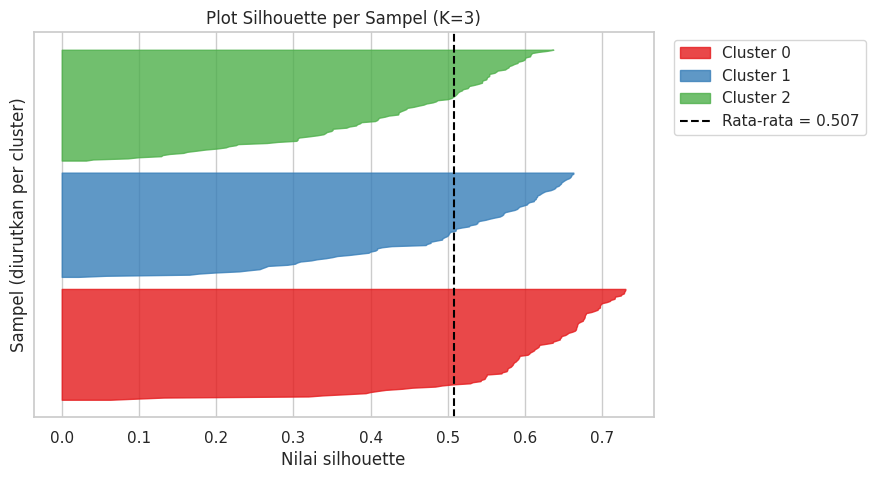

In [6]:
# Evaluasi Silhouette Score K=3 pada data ter-scaling
sil_k3 = hitung_silhouette(X_scaled, df["cluster"])
print(f"Silhouette Score (K=3, dengan scaling): {sil_k3:.4f}")

# Analisis tambahan: silhouette per sampel dan per cluster
sil_sampel = silhouette_samples(X_scaled, df["cluster"])
ringkasan_sil = (pd.Series(sil_sampel, index=df.index).groupby(df["cluster"])
                 .agg(rata_rata="mean", minimum="min", jumlah_negatif=lambda s: int((s < 0).sum())).round(3))
print("\nSilhouette per cluster:")
display(ringkasan_sil)
print(f"Jumlah sampel dengan silhouette negatif: {(sil_sampel < 0).sum()} dari {len(sil_sampel)}")

# Visualisasi distribusi silhouette per cluster
plt.figure(figsize=(8, 5))
y_bawah = 10
for c in range(3):
    nilai = np.sort(sil_sampel[df["cluster"].values == c])
    y_atas = y_bawah + len(nilai)
    plt.fill_betweenx(np.arange(y_bawah, y_atas), 0, nilai, alpha=0.8, color=palet[c], label=f"Cluster {c}")
    y_bawah = y_atas + 10
plt.axvline(sil_k3, color="black", linestyle="--", label=f"Rata-rata = {sil_k3:.3f}")
plt.title("Plot Silhouette per Sampel (K=3)")
plt.xlabel("Nilai silhouette")
plt.ylabel("Sampel (diurutkan per cluster)")
plt.yticks([])
plt.legend(loc="upper left", bbox_to_anchor=(1.02, 1))
plt.show()

**Hasil dan interpretasi:** Silhouette Score model K=3 dengan scaling adalah **0,5074**. Nilai ini berada di atas 0,5 sehingga menunjukkan struktur cluster yang **cukup baik**, namun belum mendekati 1, jadi masih ada kedekatan antarcluster. Rata-rata silhouette per cluster adalah 0,598 (Cluster 0), 0,494 (Cluster 1), dan 0,430 (Cluster 2). **Tidak ada sampel bernilai negatif** (0 dari 300), artinya tidak ada titik yang jelas salah cluster. Namun nilai minimum per cluster sangat kecil (0,022–0,063), menandakan sebagian titik berada di perbatasan cluster. Cluster 2 (pendapatan rendah, belanja sedang) adalah yang paling longgar karena sebaran skor belanja dan usianya lebih lebar serta beririsan dengan cluster lain.

## Bagian 8 — Interpretasi Profil Cluster


Profil rata-rata tiap cluster:


,usia,pendapatan,skor_belanja,jumlah_anggota
cluster,,,,
0,26.9,217.7,77.5,102
1,49.2,231.0,28.9,96
2,37.1,92.9,46.7,102



Nama cluster berdasarkan karakteristik aktual:
  Cluster 0: Muda, Pendapatan Tinggi, Belanja Tinggi
  Cluster 1: Paruh Baya, Pendapatan Tinggi, Belanja Rendah
  Cluster 2: Usia Menengah, Pendapatan Rendah, Belanja Sedang


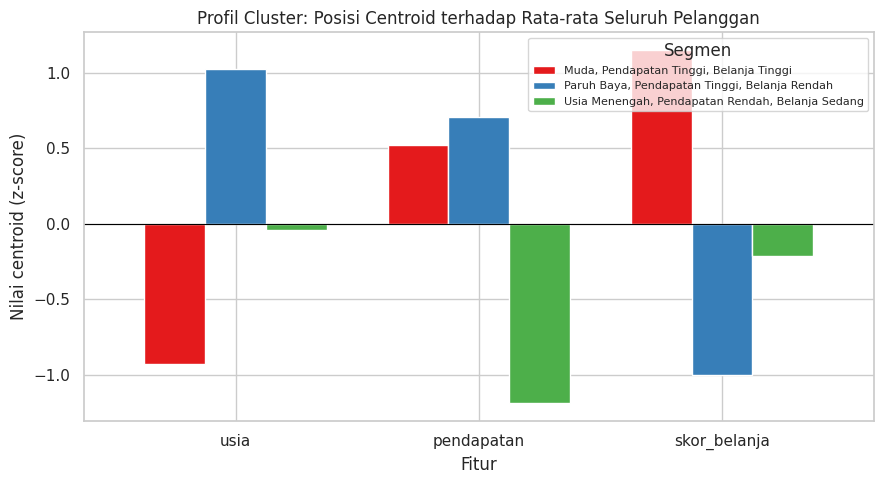

In [7]:
# Profil rata-rata fitur pada setiap cluster (skala asli)
profil = df.groupby("cluster")[["usia", "pendapatan", "skor_belanja"]].mean().round(1)
profil["jumlah_anggota"] = df["cluster"].value_counts().sort_index()
print("Profil rata-rata tiap cluster:")
display(profil)

# Pemberian nama berdasarkan nilai aktual pada tabel profil (bukan berdasarkan nomor cluster):
#  - skor belanja rata-rata tertinggi  -> kelompok belanja tinggi
#  - pendapatan rata-rata terendah     -> kelompok pendapatan lebih rendah
#  - sisanya                           -> kelompok pendapatan tinggi dengan belanja rendah
idx_belanja_tinggi = profil["skor_belanja"].idxmax()
idx_pendapatan_rendah = profil["pendapatan"].idxmin()
idx_sisa = ({0, 1, 2} - {idx_belanja_tinggi, idx_pendapatan_rendah})
assert len(idx_sisa) == 1 and idx_belanja_tinggi != idx_pendapatan_rendah, "Profil cluster tidak sesuai aturan penamaan; tinjau ulang secara manual."

nama_cluster = {
    idx_belanja_tinggi: "Muda, Pendapatan Tinggi, Belanja Tinggi",
    idx_pendapatan_rendah: "Usia Menengah, Pendapatan Rendah, Belanja Sedang",
    idx_sisa.pop(): "Paruh Baya, Pendapatan Tinggi, Belanja Rendah",
}
df["segmen"] = df["cluster"].map(nama_cluster)

print("\nNama cluster berdasarkan karakteristik aktual:")
for c in sorted(nama_cluster):
    print(f"  Cluster {c}: {nama_cluster[c]}")

# Visualisasi profil: rata-rata fitur yang dinormalisasi agar sebanding (z-score centroid)
ax = centroid_scaled.rename(index=nama_cluster).T.plot(kind="bar", figsize=(9, 5), color=palet, width=0.75)
ax.axhline(0, color="black", linewidth=0.8)
ax.set_title("Profil Cluster: Posisi Centroid terhadap Rata-rata Seluruh Pelanggan")
ax.set_xlabel("Fitur")
ax.set_ylabel("Nilai centroid (z-score)")
plt.xticks(rotation=0)
plt.legend(title="Segmen", fontsize=8)
plt.tight_layout()
plt.show()

**Interpretasi berdasarkan tabel profil:**

| Cluster | Usia | Pendapatan (juta Rp/thn) | Skor belanja | Anggota | Nama segmen |
|---|---|---|---|---|---|
| 0 | 26,9 | 217,7 | 77,5 | 102 | **Muda, Pendapatan Tinggi, Belanja Tinggi** |
| 1 | 49,2 | 231,0 | 28,9 | 96 | **Paruh Baya, Pendapatan Tinggi, Belanja Rendah** |
| 2 | 37,1 | 92,9 | 46,7 | 102 | **Usia Menengah, Pendapatan Rendah, Belanja Sedang** |

- **Cluster 0** adalah pelanggan termuda dengan pendapatan tinggi dan skor belanja tertinggi; ini kelompok paling aktif berbelanja dan bernilai tinggi bagi bisnis.
- **Cluster 1** memiliki pendapatan tertinggi (231,0) tetapi skor belanja paling rendah (28,9) dan usia tertua. Daya beli besar belum termanfaatkan sehingga kelompok ini berpotensi ditargetkan dengan program loyalitas atau penawaran yang relevan.
- **Cluster 2** berpendapatan paling rendah (92,9) dengan skor belanja sedang (46,7), sehingga cenderung sensitif terhadap harga dan cocok untuk promo/diskon.

Perbedaan utama Cluster 0 dan Cluster 1 bukan pada pendapatan (217,7 vs 231,0), melainkan pada **usia dan skor belanja**, sedangkan Cluster 2 dipisahkan terutama oleh **pendapatan**.

## Bagian 9 — Latihan Mandiri 1: Perbandingan K=3 dan K=5


Tabel perbandingan K=3 dan K=5:


,K,Inertia,Silhouette Score,Anggota terkecil,Anggota terbesar
0,3,253.6205,0.5074,96,102
1,5,182.3590,0.3828,39,100



Profil rata-rata cluster pada K=5:


,usia,pendapatan,skor_belanja,jumlah_anggota
cluster_k5,,,,
0,43.5,260.2,32.5,39
1,27.0,219.6,77.6,100
2,45.0,93.4,45.9,48
3,53.3,213.3,26.3,55
4,30.3,95.4,47.6,58



Selisih Silhouette (K=3 - K=5) = 0.1246 -> model dengan skor lebih tinggi: K=3


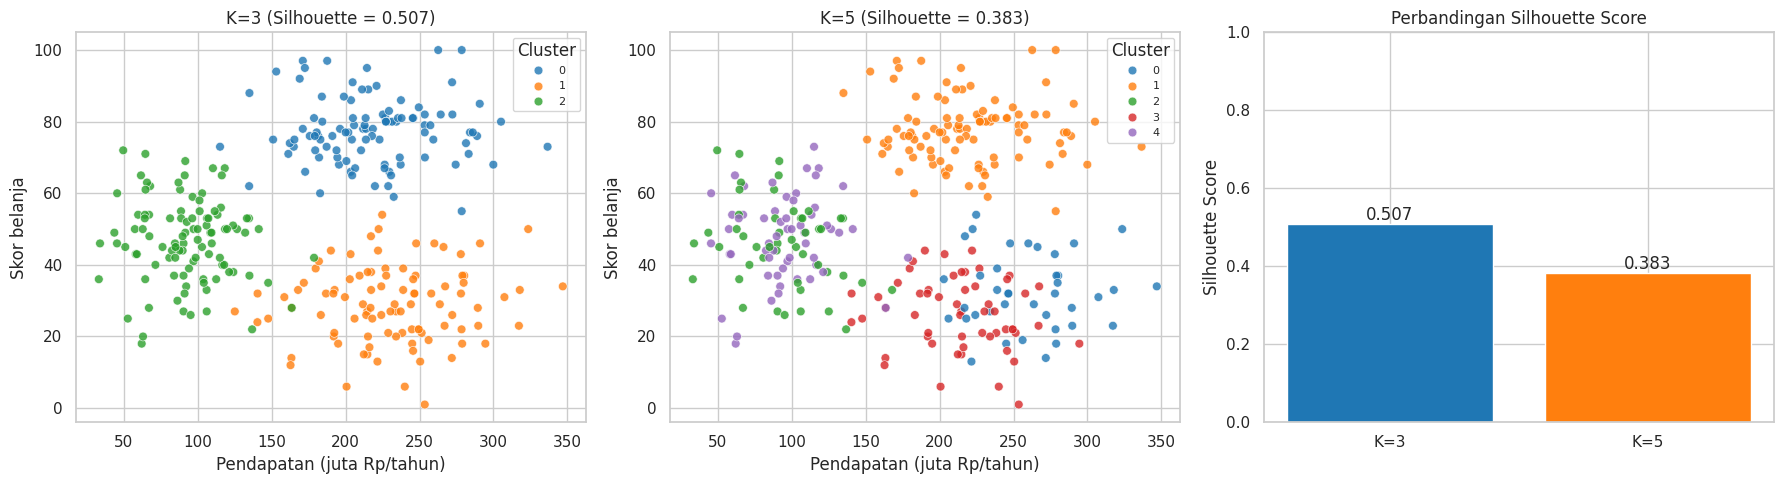

In [8]:
# Latihan Mandiri 1: K-Means K=5 vs K=3 (keduanya pada data ter-scaling)
kmeans5 = KMeans(n_clusters=5, random_state=RANDOM_STATE, n_init=10)
label_k5 = kmeans5.fit_predict(X_scaled)
df["cluster_k5"] = label_k5
sil_k5 = hitung_silhouette(X_scaled, label_k5)

tabel_k = pd.DataFrame({
    "K": [3, 5],
    "Inertia": [kmeans.inertia_, kmeans5.inertia_],
    "Silhouette Score": [sil_k3, sil_k5],
    "Anggota terkecil": [df["cluster"].value_counts().min(), pd.Series(label_k5).value_counts().min()],
    "Anggota terbesar": [df["cluster"].value_counts().max(), pd.Series(label_k5).value_counts().max()],
}).round(4)
print("Tabel perbandingan K=3 dan K=5:")
display(tabel_k)

print("\nProfil rata-rata cluster pada K=5:")
display(df.groupby("cluster_k5")[FITUR].mean().round(1).assign(jumlah_anggota=pd.Series(label_k5).value_counts().sort_index()))

selisih = sil_k3 - sil_k5
terbaik = 3 if sil_k3 > sil_k5 else 5
print(f"\nSelisih Silhouette (K=3 - K=5) = {selisih:.4f} -> model dengan skor lebih tinggi: K={terbaik}")

# Visualisasi perbandingan
fig, axes = plt.subplots(1, 3, figsize=(18, 5))
for ax, kolom, judul, n in [(axes[0], "cluster", f"K=3 (Silhouette = {sil_k3:.3f})", 3),
                             (axes[1], "cluster_k5", f"K=5 (Silhouette = {sil_k5:.3f})", 5)]:
    sns.scatterplot(data=df, x="pendapatan", y="skor_belanja", hue=kolom,
                    palette=sns.color_palette("tab10", n), s=40, alpha=0.8, ax=ax)
    ax.set_title(judul)
    ax.set_xlabel("Pendapatan (juta Rp/tahun)")
    ax.set_ylabel("Skor belanja")
    ax.legend(title="Cluster", fontsize=8)
bar = axes[2].bar(["K=3", "K=5"], [sil_k3, sil_k5], color=["tab:blue", "tab:orange"])
axes[2].bar_label(bar, fmt="%.3f")
axes[2].set_ylim(0, 1)
axes[2].set_title("Perbandingan Silhouette Score")
axes[2].set_ylabel("Silhouette Score")
plt.tight_layout()
plt.show()

**Hasil dan analisis:**

| K | Inertia | Silhouette Score | Rentang ukuran cluster |
|---|---|---|---|
| 3 | 253,62 | **0,5074** | 96–102 |
| 5 | 182,36 | 0,3828 | 39–100 |

- Inertia K=5 lebih rendah, tetapi itu **tidak otomatis berarti lebih baik** karena inertia pasti menurun saat K bertambah.
- Silhouette Score K=3 (0,5074) lebih tinggi daripada K=5 (0,3828), selisih **0,1246**. Pemisahan antarcluster pada K=3 lebih baik.
- Pada K=5, kelompok-kelompok yang sebenarnya satu segmen terpecah: kelompok pendapatan tinggi–belanja rendah terbagi menjadi dua (39 dan 55 anggota) dan kelompok pendapatan rendah juga terbagi dua (48 dan 58 anggota). Pada pasangan pendapatan rendah, skor belanja rata-ratanya hampir sama (45,9 vs 47,6) dan hanya usianya yang berbeda (45,0 vs 30,3), sehingga pemecahan ini kurang bermakna dan berpotensi menjadi *over-segmentation*.

**Kesimpulan:** Berdasarkan hasil evaluasi pada data ini, **K=3 adalah model yang lebih baik** dibandingkan K=5.

## Bagian 10 — Latihan Mandiri 2 : K-Means Tanpa Scaling


Tabel perbandingan Silhouette Score:


,Model,Silhouette (ruang model sendiri),Silhouette (ruang ter-scaling),Silhouette (ruang skala asli)
0,Dengan scaling,0.5074,0.5074,0.4436
1,Tanpa scaling,0.4613,0.2370,0.4613



Kesesuaian pengelompokan (Adjusted Rand Index) antara model ber-scaling dan tanpa scaling: 0.4926
Jumlah anggota cluster tanpa scaling: {0: 119, 1: 107, 2: 74}

Kontribusi varians tiap fitur terhadap jarak Euclidean:


,varians_asli,porsi_asli_%,varians_scaling,porsi_scaling_%
usia,129.92,2.19,1.0,33.33
pendapatan,5300.80,89.27,1.0,33.33
skor_belanja,506.98,8.54,1.0,33.33



Profil rata-rata cluster TANPA scaling:


,usia,pendapatan,skor_belanja,jumlah_anggota
cluster_tanpa_scaling,,,,
0,35.4,201.9,59.4,119
1,37.5,94.1,47.0,107
2,40.8,267.0,45.2,74


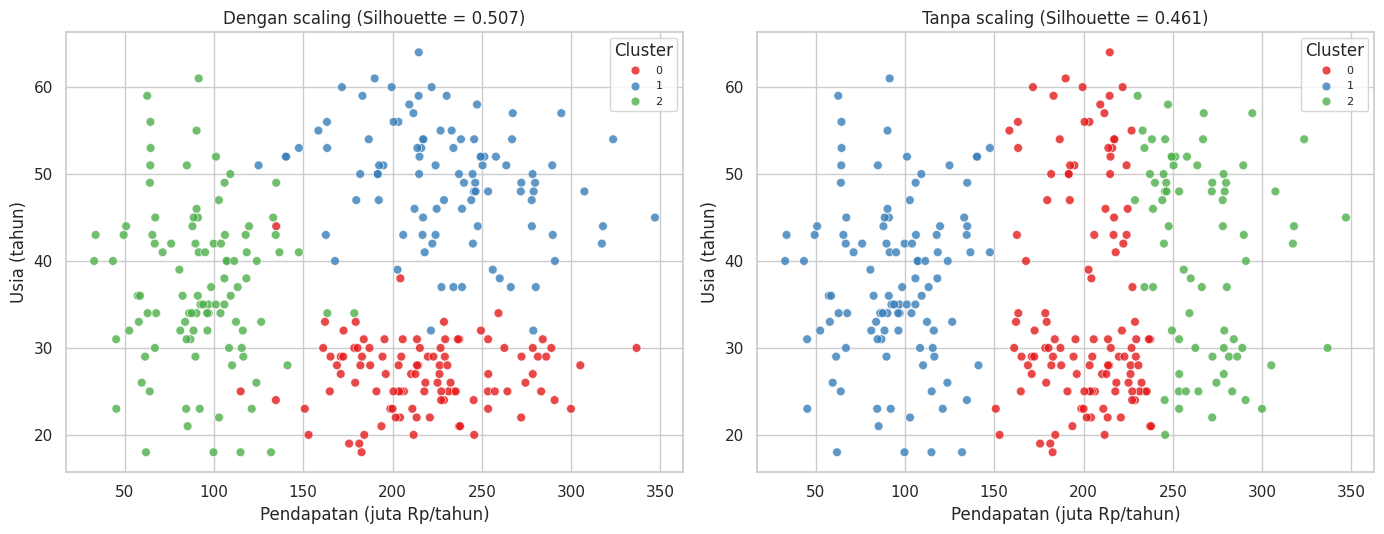

In [9]:
# Latihan Mandiri 2: K-Means K=3 TANPA scaling (fitur asli)
kmeans_raw = KMeans(n_clusters=3, random_state=RANDOM_STATE, n_init=10)
label_raw = kmeans_raw.fit_predict(X)          # X = fitur asli
df["cluster_tanpa_scaling"] = label_raw

# Silhouette masing-masing model pada representasinya sendiri (sesuai ruang tempat jarak dihitung K-Means)
sil_raw_sendiri = hitung_silhouette(X, label_raw)            # tanpa scaling, dihitung pada data asli
sil_scaled_sendiri = hitung_silhouette(X_scaled, df["cluster"])  # dengan scaling, dihitung pada data ter-scaling

# Pembanding silang: kedua label dinilai pada ruang yang SAMA
sil_raw_di_scaled = hitung_silhouette(X_scaled, label_raw)
sil_scaled_di_raw = hitung_silhouette(X, df["cluster"])

tabel_skala = pd.DataFrame({
    "Model": ["Dengan scaling", "Tanpa scaling"],
    "Silhouette (ruang model sendiri)": [sil_scaled_sendiri, sil_raw_sendiri],
    "Silhouette (ruang ter-scaling)": [sil_scaled_sendiri, sil_raw_di_scaled],
    "Silhouette (ruang skala asli)": [sil_scaled_di_raw, sil_raw_sendiri],
}).round(4)
print("Tabel perbandingan Silhouette Score:")
display(tabel_skala)

ari = adjusted_rand_score(df["cluster"], label_raw)
print(f"\nKesesuaian pengelompokan (Adjusted Rand Index) antara model ber-scaling dan tanpa scaling: {ari:.4f}")
print("Jumlah anggota cluster tanpa scaling:", {int(k): int(v) for k, v in pd.Series(label_raw).value_counts().sort_index().items()})

# Porsi varians tiap fitur: menunjukkan fitur mana yang mendominasi perhitungan jarak
porsi = pd.DataFrame({
    "varians_asli": X.var(ddof=0),
    "porsi_asli_%": X.var(ddof=0) / X.var(ddof=0).sum() * 100,
    "varians_scaling": pd.Series(X_scaled.var(axis=0), index=FITUR),
    "porsi_scaling_%": 100 * pd.Series(X_scaled.var(axis=0), index=FITUR) / X_scaled.var(axis=0).sum(),
}).round(2)
print("\nKontribusi varians tiap fitur terhadap jarak Euclidean:")
display(porsi)

print("\nProfil rata-rata cluster TANPA scaling:")
display(df.groupby("cluster_tanpa_scaling")[FITUR].mean().round(1)
        .assign(jumlah_anggota=pd.Series(label_raw).value_counts().sort_index()))

# Visualisasi: hasil dengan scaling vs tanpa scaling
fig, axes = plt.subplots(1, 2, figsize=(14, 5.5))
for ax, kolom, judul in [(axes[0], "cluster", f"Dengan scaling (Silhouette = {sil_scaled_sendiri:.3f})"),
                          (axes[1], "cluster_tanpa_scaling", f"Tanpa scaling (Silhouette = {sil_raw_sendiri:.3f})")]:
    sns.scatterplot(data=df, x="pendapatan", y="usia", hue=kolom, palette="Set1", s=40, alpha=0.8, ax=ax)
    ax.set_title(judul)
    ax.set_xlabel("Pendapatan (juta Rp/tahun)")
    ax.set_ylabel("Usia (tahun)")
    ax.legend(title="Cluster", fontsize=8)
plt.tight_layout()
plt.show()

**Hasil dan analisis:**

| Model | Silhouette (ruang model sendiri) | Silhouette (ruang ter-scaling) | Silhouette (ruang skala asli) |
|---|---|---|---|
| Dengan scaling | 0,5074 | 0,5074 | 0,4436 |
| Tanpa scaling | 0,4613 | 0,2370 | 0,4613 |

**Dampak perbedaan skala:** Pada data asli, varians `pendapatan` (5.300,8) mencakup **89,27%** dari total varians, sedangkan `skor_belanja` hanya 8,54% dan `usia` 2,19%. Akibatnya, jarak Euclidean hampir seluruhnya ditentukan oleh pendapatan. Setelah scaling, ketiga fitur masing-masing berkontribusi 33,33%.

**Dampak pada hasil clustering:** Model tanpa scaling membentuk cluster berukuran tidak seimbang (119, 107, 74) dan rata-rata usianya hampir sama (35,4; 37,5; 40,8). Cluster-cluster itu pada dasarnya hanya membedakan pendapatan rendah (94,1), menengah-tinggi (201,9), dan sangat tinggi (267,0). Kelompok muda dengan belanja tinggi tidak lagi terpisah dan bercampur dengan pelanggan lain (rata-rata skor belanja salah satu cluster hanya 59,4, bukan 77,5). *Adjusted Rand Index* antara kedua hasil hanya **0,4926**, artinya pengelompokan kedua model berbeda cukup jauh.

**Catatan penafsiran skor:** Silhouette tanpa scaling pada ruang aslinya (0,4613) secara angka tidak jauh dari 0,5074, tetapi skor itu dihitung pada ruang yang didominasi pendapatan sehingga "terlihat baik" untuk dimensi yang sama yang dipakai saat clustering. Ketika kedua hasil dinilai pada ruang ter-scaling yang seimbang, skor tanpa scaling turun menjadi **0,2370** dibandingkan **0,5074**.

**Kesimpulan:** Scaling menghasilkan cluster yang lebih seimbang, memanfaatkan ketiga fitur, dan lebih bermakna untuk segmentasi. Melewatkan scaling membuat fitur berskala besar mendominasi sehingga informasi `usia` dan `skor_belanja` hampir tidak berpengaruh.

## Bagian 11 — Latihan Mandiri 3: Scatter Plot Usia vs Skor Belanja
Scatter plot menggunakan nilai **asli** `usia` (sumbu X) dan `skor_belanja` (sumbu Y) agar mudah dibaca, dengan warna sesuai cluster hasil K-Means K=3 dan tanda X untuk centroid pada skala asli.

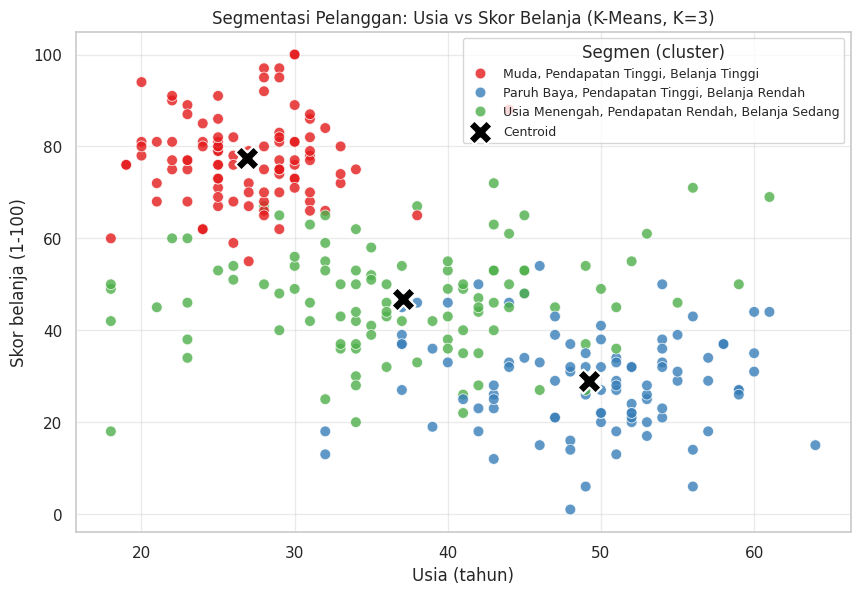

usia           skor_belanja  \
                                                  min  mean max          min   
segmen                                                                         
Muda, Pendapatan Tinggi, Belanja Tinggi            18  26.9  44           55   
Paruh Baya, Pendapatan Tinggi, Belanja Rendah      32  49.2  64            1   
Usia Menengah, Pendapatan Rendah, Belanja Sedang   18  37.1  61           18   

                                                             
                                                  mean  max  
segmen                                                       
Muda, Pendapatan Tinggi, Belanja Tinggi           77.5  100  
Paruh Baya, Pendapatan Tinggi, Belanja Rendah     28.9   54  
Usia Menengah, Pendapatan Rendah, Belanja Sedang  46.7   72

In [10]:
# Latihan Mandiri 3: Scatter plot usia (x) vs skor belanja (y), warna = cluster K=3 (skala asli)
plt.figure(figsize=(10, 6.5))
urutan_segmen = [nama_cluster[c] for c in sorted(nama_cluster)]
ax = sns.scatterplot(data=df, x="usia", y="skor_belanja", hue="segmen", hue_order=urutan_segmen,
                     palette="Set1", s=60, alpha=0.8, edgecolor="white")
# Centroid pada skala asli
plt.scatter(centroid_asli["usia"], centroid_asli["skor_belanja"], marker="X", s=300,
            c="black", edgecolor="white", linewidth=1.5, label="Centroid", zorder=5)
plt.title("Segmentasi Pelanggan: Usia vs Skor Belanja (K-Means, K=3)")
plt.xlabel("Usia (tahun)")
plt.ylabel("Skor belanja (1-100)")
plt.legend(title="Segmen (cluster)", fontsize=9, loc="best")
plt.grid(True, alpha=0.4)
plt.show()

# Ringkasan rentang usia dan skor belanja per segmen untuk membantu membaca pola
display(df.groupby("segmen")[["usia", "skor_belanja"]].agg(["min", "mean", "max"]).round(1))

**Pola yang terlihat:**
- **Muda, Pendapatan Tinggi, Belanja Tinggi:** berkumpul di sisi kiri atas (usia 18–44, rata-rata 26,9) dengan skor belanja tinggi (55–100, rata-rata 77,5).
- **Paruh Baya, Pendapatan Tinggi, Belanja Rendah:** berada di sisi kanan bawah (usia 32–64, rata-rata 49,2) dengan skor belanja rendah (1–54, rata-rata 28,9).
- **Usia Menengah, Pendapatan Rendah, Belanja Sedang:** berada di area tengah (usia 18–61, skor belanja 18–72) dan tampak **bertumpang tindih** dengan dua cluster lain pada bidang ini.

Secara umum terdapat kecenderungan bahwa pelanggan yang lebih muda memiliki skor belanja lebih tinggi. Tumpang tindih pada cluster tengah wajar karena cluster tersebut dipisahkan terutama oleh **pendapatan**, yang tidak tampak pada grafik dua dimensi usia–skor belanja ini.

## Ringkasan Angka Hasil Eksperimen
Sel berikut mengumpulkan seluruh hasil utama dari variabel yang telah dihitung sebagai dasar penulisan refleksi dan kesimpulan.

In [11]:
# Ringkasan seluruh hasil eksperimen (nilai diambil langsung dari variabel hasil eksekusi)
ringkasan = pd.DataFrame({
    "Eksperimen": [
        "K-Means K=3 + scaling (model utama)",
        "K-Means K=5 + scaling",
        "K-Means K=3 tanpa scaling",
    ],
    "Silhouette (ruang ter-scaling)": [sil_k3, sil_k5, sil_raw_di_scaled],
    "Silhouette (ruang model sendiri)": [sil_k3, sil_k5, sil_raw_sendiri],
    "Anggota terkecil": [df["cluster"].value_counts().min(),
                         df["cluster_k5"].value_counts().min(),
                         df["cluster_tanpa_scaling"].value_counts().min()],
}).round(4)
display(ringkasan)
print(f"Inertia K=1..10: {[round(v, 1) for v in inertias]}")
print(f"Penurunan inertia K=2->3: {tabel_elbow.loc[2, 'penurunan_%']:.1f}% | K=3->4: {tabel_elbow.loc[3, 'penurunan_%']:.1f}%")
print(f"Adjusted Rand Index (dengan vs tanpa scaling): {ari:.4f}")

,Eksperimen,Silhouette (ruang ter-scaling),Silhouette (ruang model sendiri),Anggota terkecil
0,K-Means K=3 + scaling (model utama),0.5074,0.5074,96
1,K-Means K=5 + scaling,0.3828,0.3828,39
2,K-Means K=3 tanpa scaling,0.2370,0.4613,74


Inertia K=1..10: [900.0, 503.5, 253.6, 209.8, 182.4, 163.3, 148.5, 141.8, 128.1, 119.8]
Penurunan inertia K=2->3: 49.6% | K=3->4: 17.3%
Adjusted Rand Index (dengan vs tanpa scaling): 0.4926


## Bagian 12 — Refleksi

**1. Bagaimana K-Means menemukan kelompok tanpa label?**

K-Means tidak memerlukan label karena hanya memanfaatkan **kemiripan (jarak) antar data**. Algoritma menempatkan K centroid awal, lalu mengulang dua langkah: menetapkan setiap pelanggan ke centroid terdekat, dan menghitung ulang centroid sebagai rata-rata anggotanya. Proses ini menurunkan inertia secara bertahap hingga konvergen; pada eksperimen ini konvergen dalam 6 iterasi dan menghasilkan inertia 253,62. Karena awal centroid dapat memengaruhi hasil, digunakan `n_init=10`. Hasilnya adalah tiga kelompok (102, 96, 102 anggota) dengan profil yang jelas berbeda, tanpa pernah menggunakan informasi kelompok asal data. Makna kelompok baru ditetapkan setelah clustering, dengan membaca profil rata-rata tiap cluster.

**2. Mengapa metode Elbow menunjukkan siku di K=3 pada data ini?**

Pada eksperimen ini grafik Elbow memang menunjukkan siku yang cukup jelas di K=3: inertia turun 49,6% dari K=2 ke K=3, tetapi hanya 17,3% dari K=3 ke K=4 dan semakin kecil setelahnya. Penyebabnya adalah struktur data: dataset dibangkitkan dari tiga kelompok yang berbeda dalam kombinasi usia, pendapatan, dan skor belanja. Selama K di bawah 3, ada kelompok sebenarnya yang digabung sehingga jarak ke centroid besar; ketika K=3, setiap kelompok memiliki centroid sendiri sehingga penurunan berikutnya hanya berasal dari pemecahan variasi acak di dalam kelompok. Silhouette Score tertinggi pada K=3 (0,507) mendukung temuan ini. Perlu diingat bahwa pada data nyata, siku bisa kurang tegas dan tidak selalu sesuai dengan teori modul.

**3. Mengapa scaling penting, dan apa dampaknya bila dilewatkan?**

K-Means menghitung jarak Euclidean, sehingga fitur berskala besar menguasai perhitungan. Pada data ini, tanpa scaling, `pendapatan` menyumbang sekitar 89% dari total varians, sedangkan `skor_belanja` 8,5% dan `usia` 2,2%. Dampaknya terlihat pada hasil eksperimen: cluster tanpa scaling berukuran tidak seimbang (119, 107, 74), rata-rata usia antarcluster hampir sama (35,4–40,8), dan kelompok muda dengan belanja tinggi tidak terpisah dengan baik. Kesesuaian pengelompokannya dengan model ber-scaling hanya 0,49 (Adjusted Rand Index), dan bila dinilai pada ruang ter-scaling yang seimbang, Silhouette Score-nya turun ke 0,237 dibandingkan 0,507. Selain itu, skor tanpa scaling pada ruang aslinya (0,461) tampak tidak jauh berbeda, sehingga angka silhouette saja bisa menyesatkan jika ruang fitur tidak diperhatikan.